# Team 16 (Jigaz): Week 2 EDA + Preprocessing

**Project:** Heart Disease prediction (binary classification)
**Target:** `HeartDisease` (1 = heart disease, 0 = normal)
**Dataset:** UCI Heart Disease data (combined Cleveland, Hungary, Switzerland, VA Long Beach), 920 rows x 16 columns in the file `heart_disease_uci.csv`.
The proposal refers to the Kaggle version (918 rows, 12 columns). The Kaggle version is the same four-source collection with renamed columns; the cholesterol zeros (172 rows) match it exactly, so this file is used here.

**Hypothesis (from the proposal):** `ST_Slope`, `ChestPainType` and `Oldpeak` are stronger predictors of `HeartDisease` than `Age` and `Cholesterol`. We check this in the EDA below.

**Order of work:** the steps that do not learn anything from the data (dropping columns, fixing invalid zeros, encoding with fixed categories) are done first. Then the train/test split is made. Only after the split are the imputation values and the scaler fitted, and they are fitted on the training part only, to avoid data leakage.

## 1. Imports and loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

raw = pd.read_csv('../data/heart_disease_uci.csv')
raw.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 2. Dataset overview

Shape, data types, missing values and descriptive statistics of the raw file, before any cleaning.

In [2]:
print('Shape:', raw.shape)
print('\nData types:')
print(raw.dtypes)
print('\nMissing values per column:')
print(raw.isnull().sum())
raw.describe(include='all').T

Shape: (920, 16)

Data types:
id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object

Missing values per column:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


**Summary of the dataset.** The file has 920 patients from four clinical sources. Each row has 16 columns: demographics (`age`, `sex`), symptoms and exam results (`cp`, `trestbps`, `chol`, `fbs`, `restecg`, `thalch`, `exang`, `oldpeak`, `slope`), two clinical measurements with heavy missingness (`ca`, `thal`), the source site (`dataset`), an id, and the diagnosis `num` (0 to 4 severity). We predict whether a patient has heart disease. `num` is turned into a binary target `HeartDisease` (0 = no disease, 1 = any disease). Several columns have many missing values, and `chol` and `trestbps` contain physiologically impossible zeros. Both problems are handled in section 4.

## 3. Target and class distribution

HeartDisease
1    509
0    411
Name: count, dtype: int64
HeartDisease
1    55.3
0    44.7
Name: proportion, dtype: float64


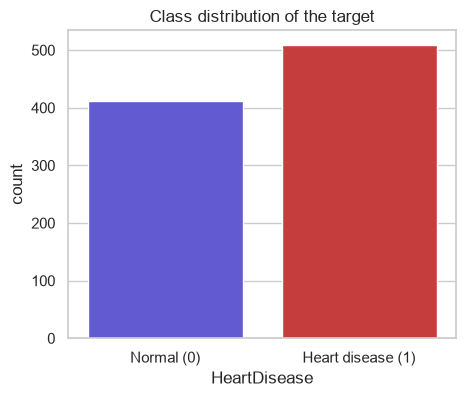

In [3]:
df = raw.copy()
df['HeartDisease'] = (df['num'] > 0).astype(int)

print(df['HeartDisease'].value_counts())
print((df['HeartDisease'].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x='HeartDisease', hue='HeartDisease', data=df, palette=['#4f46e5', '#dc2626'], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Normal (0)', 'Heart disease (1)'])
ax.set_title('Class distribution of the target')
plt.show()

**Interpretation.** 509 patients (55.3%) have heart disease and 411 (44.7%) do not. The classes are reasonably balanced, so accuracy is usable, but we will also report F1 and ROC AUC in Week 3 because they are more informative than accuracy when classes are unequal.

## 4. Cleaning decisions (no statistics learned from data here)

The table below shows every column with missing values after replacing the invalid zeros. Each column gets its own decision.

| Column | Decision | Reason |
|---|---|---|
| `id`, `num`, `dataset` | Drop | `id` is a row number. `num` is replaced by the binary target. `dataset` is the source hospital, not a patient measurement, and is not one of the 11 features in our proposal. |
| `ca` (about 66% missing) | Drop | More than half the values are missing, and it is not in the proposal. |
| `thal` (about 53% missing) | Drop | More than half the values are missing, and it is not in the proposal. |
| `chol` | Zero to NaN, then median imputation (fitted on train) | A cholesterol value of 0 is physiologically impossible; these are missing values. Median is used because cholesterol is skewed by outliers. |
| `trestbps` | Zero to NaN, then median imputation (fitted on train) | Same reasoning as cholesterol: a resting blood pressure of 0 is impossible. |
| `thalch`, `oldpeak` | Median imputation (fitted on train) | Numeric, few missing values; the median is robust to outliers. |
| `fbs`, `exang` | Mode imputation (fitted on train) | Binary (True/False). Most common value keeps them as 0/1. |
| `restecg`, `slope` | Flag as a separate category `Unknown` | Nominal categories. Missing is not the same as any real category, so we keep it as its own level. It also keeps the 309 patients with no slope information instead of guessing their slope. |

In [4]:
KEEP = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
        'thalch', 'exang', 'oldpeak', 'slope']
df = df[KEEP + ['HeartDisease']].copy()

df['chol'] = df['chol'].replace(0, np.nan)
df['trestbps'] = df['trestbps'].replace(0, np.nan)

df['sex'] = df['sex'].map({'Male': 1, 'Female': 0})
df['exang'] = df['exang'].map({True: 1, False: 0, 'True': 1, 'False': 0})
df['fbs'] = df['fbs'].map({True: 1, False: 0, 'True': 1, 'False': 0})

for c in ['restecg', 'slope', 'cp']:
    df[c] = df[c].fillna('Unknown')

missing = pd.DataFrame({'missing': df.isnull().sum(),
                        'percent': (df.isnull().mean() * 100).round(1)})
missing[missing['missing'] > 0]

,missing,percent
trestbps,60,6.5
chol,202,22.0
fbs,90,9.8
thalch,55,6.0
exang,55,6.0
oldpeak,62,6.7


Row count is kept at 920: no rows are dropped. Dropping the 172 rows with zero cholesterol would throw away almost a fifth of the data (18.7%), so we impute instead.

## 5. Exploratory data analysis

The plots below use the cleaned data (with missing cholesterol and blood pressure values shown as NaN, so they do not distort the plots).

### 5.1 Age distribution by diagnosis

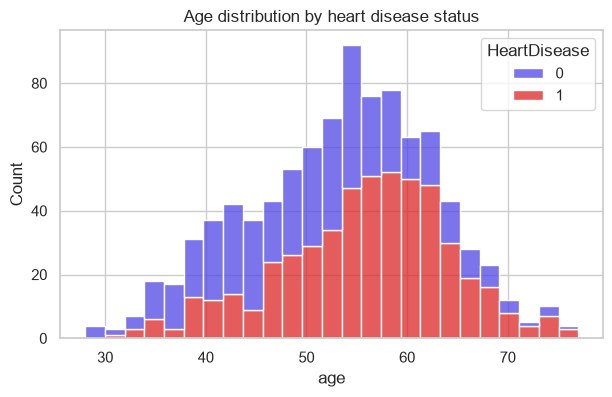

In [5]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='age', hue='HeartDisease', bins=25, multiple='stack',
             palette=['#4f46e5', '#dc2626'])
plt.title('Age distribution by heart disease status')
plt.show()

**Interpretation.** Patients with heart disease are older on average (median 57 vs 51 years), but the two groups overlap a lot across all ages. Age alone is therefore a moderate predictor, which fits the proposal's claim that it is weaker than the exercise and chest-pain features.

### 5.2 Maximum heart rate by diagnosis (boxplot by category)

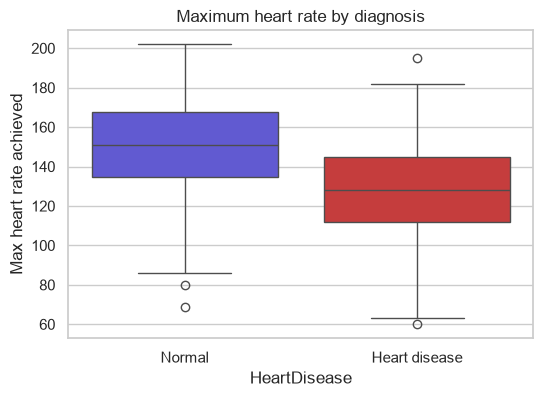

In [6]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='HeartDisease', y='thalch', hue='HeartDisease', data=df, palette=['#4f46e5', '#dc2626'], legend=False)
plt.xticks([0, 1], ['Normal', 'Heart disease'])
plt.ylabel('Max heart rate achieved')
plt.title('Maximum heart rate by diagnosis')
plt.show()

**Interpretation.** Patients with heart disease reach a lower maximum heart rate during exercise (median about 128 vs 151 bpm). The two boxes barely overlap, so this variable separates the classes well and is a strong predictor. It is also the variable the proposal uses for the "age-predicted maximum" feature engineered in section 6.

### 5.3 Chest pain type by diagnosis (countplot)

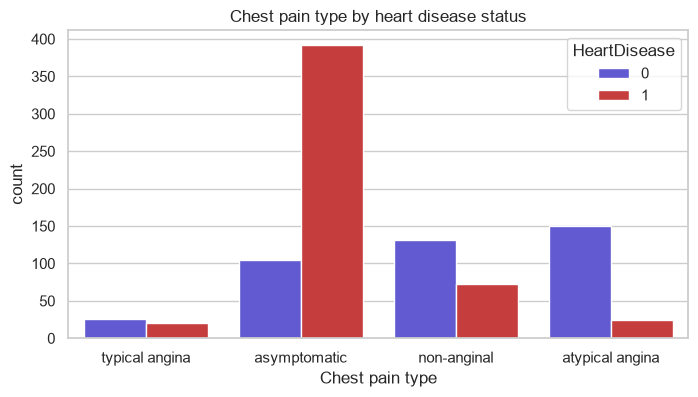

In [7]:
plt.figure(figsize=(8, 4))
sns.countplot(x='cp', hue='HeartDisease', data=df, palette=['#4f46e5', '#dc2626'])
plt.title('Chest pain type by heart disease status')
plt.xlabel('Chest pain type')
plt.show()

**Interpretation.** Asymptomatic chest pain (`asymptomatic`) is by far the most common in patients with heart disease: about 79% of the asymptomatic group have the disease, against 14% for atypical angina. Chest pain type is therefore one of the strongest categorical predictors, as the proposal expected.

### 5.4 ST slope by diagnosis (countplot)

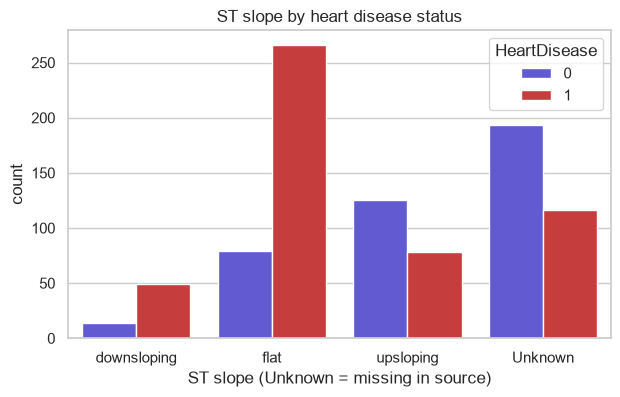

In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(x='slope', hue='HeartDisease', data=df, palette=['#4f46e5', '#dc2626'])
plt.title('ST slope by heart disease status')
plt.xlabel('ST slope (Unknown = missing in source)')
plt.show()

**Interpretation.** Flat (77%) and downsloping (78%) ST segments are associated with heart disease, while upsloping segments are not (38%). Patients with an unknown slope have a disease rate of 37.5%, close to the upsloping group, which supports keeping them as their own category rather than guessing a slope. This confirms the proposal's hypothesis that ST_Slope is a strong predictor.

### 5.5 ST depression (oldpeak) by diagnosis

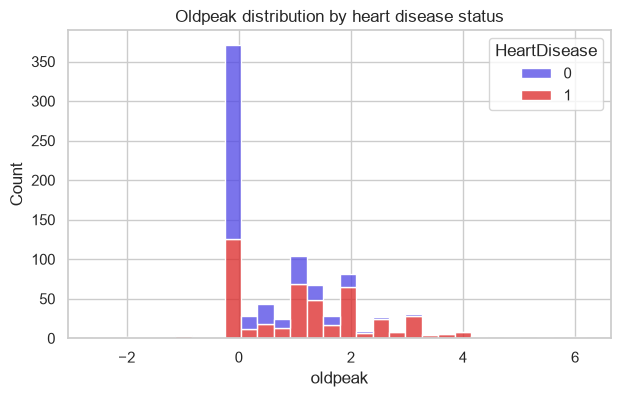

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='oldpeak', hue='HeartDisease', bins=30, multiple='stack',
             palette=['#4f46e5', '#dc2626'])
plt.title('Oldpeak distribution by heart disease status')
plt.show()

**Interpretation.** Most patients without disease have an oldpeak of 0, while the disease group is spread over higher values (median 1.05 vs 0). Higher ST depression therefore goes with heart disease, consistent with the proposal. Note the small number of negative values, which are kept because they are valid measurements.

### 5.6 Cholesterol by diagnosis (boxplot by category)

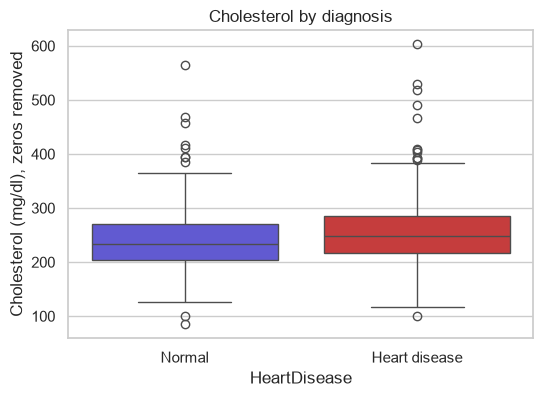

In [10]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='HeartDisease', y='chol', hue='HeartDisease', data=df, palette=['#4f46e5', '#dc2626'], legend=False)
plt.xticks([0, 1], ['Normal', 'Heart disease'])
plt.ylabel('Cholesterol (mg/dl), zeros removed')
plt.title('Cholesterol by diagnosis')
plt.show()

**Interpretation.** After removing the impossible zeros, the median cholesterol is 248 mg/dl in the disease group and 233 in the normal group. The distributions overlap heavily, and the correlation with the target is only about +0.12, so cholesterol is a weak predictor. This agrees with the proposal's hypothesis that it is less informative than the ST and chest-pain features.

### 5.7 Correlation heatmap

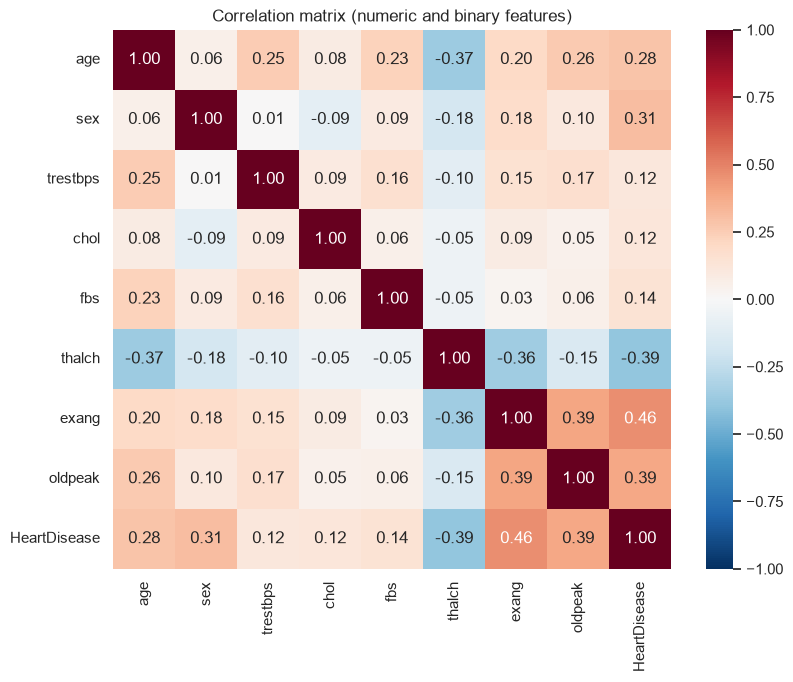

In [11]:
num_for_corr = ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak', 'HeartDisease']
corr = df[num_for_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix (numeric and binary features)')
plt.show()

**Interpretation.** The strongest correlation with the target is `exang` (exercise-induced angina, about +0.46), followed by `oldpeak` (+0.39), `thalch` (-0.39) and `age` (+0.28). `chol` (+0.12) and `trestbps` are weakly correlated with the target. Exercise angina was not in the proposal's hypothesis, but it is at least as strong as the features it proposed. Among the features themselves, `age` and `thalch` are negatively correlated, which is expected because maximum heart rate falls with age; this is the motivation for the engineered feature in section 6.

## 6. Feature engineering and encoding

**New feature: `HR_reserve`.** The maximum heart rate expected for a healthy person of a given age is about `220 - age`. The difference `(220 - age) - thalch` is how far a patient's achieved heart rate falls below the age-predicted maximum. Patients with heart disease often cannot reach their expected heart rate during exercise, so a large positive value is a plausible sign of cardiac stress. This is a direct clinical transformation of two existing columns and is recorded here before modelling.

**Encoding decisions.**
- `sex`, `exang`, `fbs` are binary, so they are already coded 0/1. No encoding is needed.
- `cp` (4 levels), `restecg` (3 levels + Unknown) and `slope` (3 levels + Unknown) are nominal with low cardinality. They have no natural order (for example, `asymptomatic` is not "bigger" than `atypical angina`), so **one-hot encoding** is used. Ordinal or label encoding would make the model assume a numeric spacing that does not exist. One-hot is suitable for both linear models (such as logistic regression) and tree models, the families we plan to use in Week 3.

In [12]:
df['HR_reserve'] = (220 - df['age']) - df['thalch']

cat_cols = ['cp', 'restecg', 'slope']
df_enc = pd.get_dummies(df, columns=cat_cols, prefix=cat_cols, dtype=int)

print('Columns after encoding:', df_enc.shape[1])
print(list(df_enc.columns))
df_enc.head()

Columns after encoding: 22
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak', 'HeartDisease', 'HR_reserve', 'cp_asymptomatic', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'restecg_Unknown', 'restecg_lv hypertrophy', 'restecg_normal', 'restecg_st-t abnormality', 'slope_Unknown', 'slope_downsloping', 'slope_flat', 'slope_upsloping']


,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,HeartDisease,HR_reserve,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_Unknown,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,slope_Unknown,slope_downsloping,slope_flat,slope_upsloping
0,63,1,145.0,233.0,1.0,150.0,0.0,2.3,0,7.0,0,0,0,1,0,1,0,0,0,1,0,0
1,67,1,160.0,286.0,0.0,108.0,1.0,1.5,1,45.0,1,0,0,0,0,1,0,0,0,0,1,0
2,67,1,120.0,229.0,0.0,129.0,1.0,2.6,1,24.0,1,0,0,0,0,1,0,0,0,0,1,0
3,37,1,130.0,250.0,0.0,187.0,0.0,3.5,0,-4.0,0,0,1,0,0,0,1,0,0,1,0,0
4,41,0,130.0,204.0,0.0,172.0,0.0,1.4,0,7.0,0,1,0,0,0,1,0,0,0,0,0,1


## 7. Train/test split

The split is done **before** any statistic is computed for imputation or scaling. We use `test_size=0.2` (80% train, 20% test) and `random_state=42` for reproducibility. `stratify=y` keeps the class proportions the same in both parts.

In [13]:
X = df_enc.drop(columns='HeartDisease')
y = df_enc['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])
print('Train class balance:', round(y_train.mean(), 3), '| Test class balance:', round(y_test.mean(), 3))

Train size: 736 | Test size: 184
Train class balance: 0.553 | Test class balance: 0.554


## 8. Imputation and scaling (fitted on training data only)

Imputation values and the scaler's mean and standard deviation are learned from `X_train` (`fit_transform`). The same learned values are then applied to `X_test` (`transform`). The test set is never used to compute any statistic, so no information leaks from it into the model.

**Scaler choice: `StandardScaler`.** The numeric features (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `HR_reserve`) are on very different scales (for example cholesterol in the hundreds, oldpeak below 7). Distance-based and gradient-based models, such as logistic regression, SVM and KNN, are sensitive to scale, so scaling is needed. `StandardScaler` centres each feature at zero with unit variance; the numeric features are roughly bell-shaped after imputation, which suits this choice. Binary and one-hot columns are already 0/1 and are not scaled.

In [14]:
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'HR_reserve']
bin_cols = ['sex', 'exang', 'fbs']

X_train = X_train.copy()
X_test = X_test.copy()

imp_num = SimpleImputer(strategy='median')
imp_bin = SimpleImputer(strategy='most_frequent')
X_train[num_cols] = imp_num.fit_transform(X_train[num_cols])
X_test[num_cols] = imp_num.transform(X_test[num_cols])
X_train[bin_cols] = imp_bin.fit_transform(X_train[bin_cols])
X_test[bin_cols] = imp_bin.transform(X_test[bin_cols])

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print('Learned training means of scaled features (before scaling):', dict(zip(num_cols, np.round(scaler.mean_, 2))))

Learned training means of scaled features (before scaling): {'age': np.float64(53.59), 'trestbps': np.float64(132.08), 'chol': np.float64(244.95), 'thalch': np.float64(137.79), 'oldpeak': np.float64(0.86), 'HR_reserve': np.float64(28.99)}


## 9. Final check of the split and preprocessing

The shapes of the four arrays are printed and confirmed, and the notebook checks that no missing values remain.

In [15]:
print('X_train.shape:', X_train.shape)
print('X_test.shape: ', X_test.shape)
print('y_train.shape:', y_train.shape)
print('y_test.shape: ', y_test.shape)

assert X_train.shape[0] + X_test.shape[0] == len(df_enc)
assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0
print('Shapes confirmed. No missing values remain in X_train or X_test.')

X_train.shape: (736, 21)
X_test.shape:  (184, 21)
y_train.shape: (736,)
y_test.shape:  (184,)
Shapes confirmed. No missing values remain in X_train or X_test.
